In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms


import numpy as np
import matplotlib.pyplot as plt



from PIL import Image, ImageDraw
from google.colab import drive

import os
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets
import torchvision.utils as vutils
from torch.utils.data import Subset


try:
  import torchdiff
except ImportError:
  !pip install torchdiff


from torchdiff.sde import SchedulerSDE, ForwardSDE, ReverseSDE, TrainSDE, SampleSDE
from torchdiff.utils import TextEncoder, Metrics, snr_capped_loss, mse_loss, DiffusionNetwork


if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    print('GPU indisponible, CPU à la place.')
    DEVICE = torch.device("cpu")



#montage du drive
drive.mount('/content/drive')

IMG_SIZE = 28
SAVE_DIR = "/content/drive/MyDrive/circle_dataset" #répertoire de sauvegarde sur le drive

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 56.7 MB/s eta 0:00:00
Mounted at /content/drive


# Test de la méthode SGM sur des images de cercles

## Génération de l'ensemble de données

In [ ]:
# fonction créant une base de données de n_samples images de cercles sur fond noir
# dans le repertoire save_dir. Dans save_dir, deux fichiers en format numpy s'y trouvent:
# X.npy (chaque ligne stocke une image) et y.npy (stockant le rayon du cercle de chaque image).
# Le rayon des cercles varie entre r_min et r_max
def generate_dataset(n_samples, save_dir,img_size,r_min=3,r_max=10):
    X = np.zeros((n_samples, img_size, img_size), dtype=np.uint8)
    y = np.zeros(n_samples)

    for i in range(n_samples):
        img = Image.new("L", (img_size, img_size), 0)
        draw = ImageDraw.Draw(img)

        radius = np.random.randint(r_min, r_max)
        x_pos = np.random.randint(radius, img_size - radius)
        y_pos = np.random.randint(radius, img_size - radius)

        bbox = [x_pos-radius, y_pos-radius, x_pos+radius, y_pos+radius]
        draw.ellipse(bbox, outline=255,width=1)

        X[i] = np.array(img)
        y[i] = radius  # label = rayon

    np.save(f"{save_dir}/X.npy", X)
    np.save(f"{save_dir}/y.npy", y)


In [ ]:
# À ne pas exécuter si a déjà été exécuté une fois

# création des répertoires SAVE_DIR/train et SAVE_DIR/valid
for split in ["train", "valid"]:
    os.makedirs(f"{SAVE_DIR}/{split}", exist_ok=True)

# génération des datasets de cercles train et valid
train_rep = f"{SAVE_DIR}/train"
valid_rep = f"{SAVE_DIR}/valid"
generate_dataset(8000, train_rep,IMG_SIZE)
generate_dataset(2000, valid_rep,IMG_SIZE)

In [ ]:
# facilite la gestion des datasets de cercle
class CircleDataset(torch.utils.data.Dataset):
    def __init__(self, data_dir):
        self.X = np.load(f"{data_dir}/X.npy").astype(np.float32)
        self.y = np.load(f"{data_dir}/y.npy").astype(np.float32)
        self.X = ((self.X/255.0) - 0.5)/0.5

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32).unsqueeze(0)
        y = torch.tensor(self.y[idx], dtype=torch.float32)
        return x,y

In [ ]:
# Chargement des images
train_rep = f"{SAVE_DIR}/train"
valid_rep = f"{SAVE_DIR}/valid"
batch_size = 64

c_train_loader = DataLoader(CircleDataset(train_rep), batch_size=batch_size)
c_valid_loader = DataLoader(CircleDataset(valid_rep), batch_size=batch_size)

In [ ]:
def show_images(loader,grid_size=(8, 8)):
    x, y = next(iter(loader))
    x = x.squeeze(1)
    x = (x * 0.5 + 0.5).clamp(0,1)
    fig, axes = plt.subplots(grid_size[0], grid_size[1], figsize=(10,10))
    for i, ax in enumerate(axes.flat):
        ax.imshow(x[i], cmap='gray')
        ax.axis('off')
    plt.show()

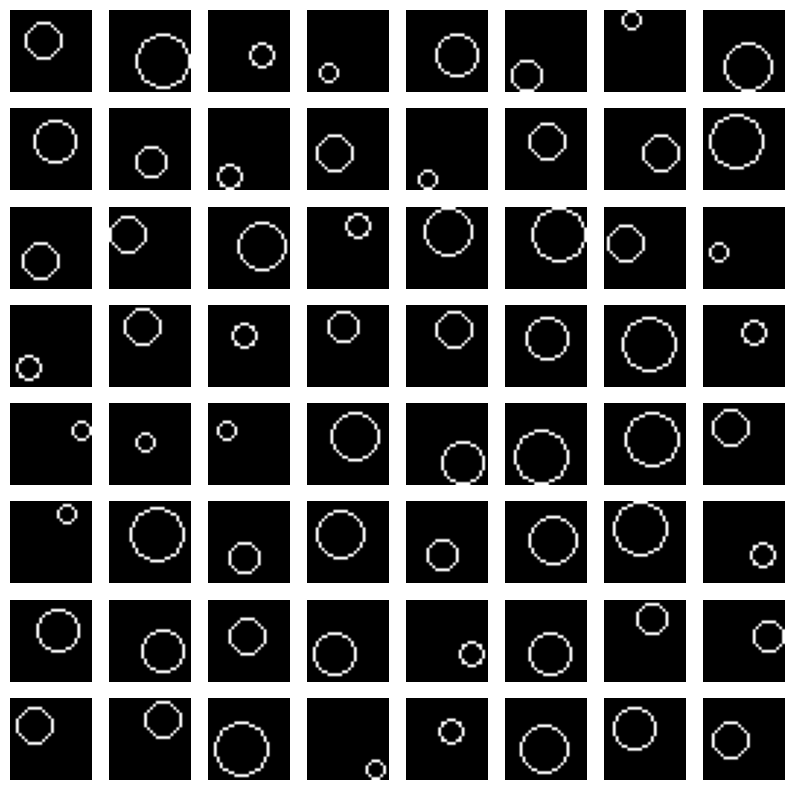

In [ ]:
show_images(c_train_loader)

## Entraînement et stockage du réseau prédisant le score

In [ ]:
# À ne pas exécuter si a déjà été exécuté une fois

# score_net : réseau de neurones utilisés (U-net) pour prévoir le score ou le bruit
diff_net = DiffusionNetwork(
    in_channels = 1,
    down_channels = [32, 64, 128, 256],
    mid_channels = [256, 256, 256],
    up_channels = [256, 128, 64, 32],
    down_sampling = [True, True, True],
    time_embed_dim = 256,
    y_embed_dim = 256,
    num_down_blocks = 2,
    num_mid_blocks =  2,
    num_up_blocks = 2,
    down_sampling_factor = 2,
    cont_time = True,
    use_flash_attention = True
).to(DEVICE)



# Métriques d'évaluation
metrics = Metrics(device=DEVICE, fid=False, metrics=True, lpips_=False)

# Optimiseur
optim = torch.optim.AdamW(
    [p for p in diff_net.parameters()], lr=1e-4
)

# Paramètres pour décrire les SDE de diffusion
vs = SchedulerSDE("linear")
fwd = ForwardSDE(vs, "vp", 'noise')
rev = ReverseSDE(vs, "vp", 'noise')

In [ ]:
# Entrainement du score_net
def training(_fwd,_rev,_score_net,_optim,train_loader,valid_loader,nb_epochs,metrics=None,text_enc=None):
  trainer = TrainSDE(
    score_net = _score_net,
    fwd_sde = _fwd,
    rwd_sde = _rev,
    optim = _optim,
    loss_fn = mse_loss,
    cond_net = text_enc,
    train_loader = train_loader,
    val_loader = valid_loader,
    max_epochs = nb_epochs,
    device = DEVICE,
    grad_acc = 2,
    log_freq = 1,
    warmup_steps = 8000,
    metrics_ = metrics
  )
  return trainer()

# Sauvegarde du score_net et de l'optimiseur dans le fichier filepath
def save_model_optim(_score_net,_optim, filepath):
  torch.save({
    'model_state_dict': diff_net.state_dict(),
    'optimizer_state_dict': optim.state_dict()
   }, filepath)



In [ ]:
# À ne pas exécuter si a déjà été exécuté une fois

#Entrainement
training(fwd,rev,diff_net,optim,c_train_loader,c_valid_loader,65,metrics=metrics)

#Sauvegarde
checkpoint_path = f"{SAVE_DIR}/checkpoint.pth"
save_model_optim(diff_net,optim, checkpoint_path)

Epoch 1/65: 100%|██████████| 125/125 [00:01<00:00, 64.24it/s, Loss=0.1898]



Epoch: 1/65 | LR: 1.07e-05 | Train Loss: 0.1853

Model saved at epoch 1 with loss: 0.1853


Epoch 2/65: 100%|██████████| 125/125 [00:01<00:00, 64.35it/s, Loss=0.2089]



Epoch: 2/65 | LR: 1.14e-05 | Train Loss: 0.1899



Epoch 3/65: 100%|██████████| 125/125 [00:01<00:00, 64.45it/s, Loss=0.1683]


...


Epoch: 42/65 | LR: 3.93e-05 | Train Loss: 0.1880



Epoch 43/65: 100%|██████████| 125/125 [00:01<00:00, 68.02it/s, Loss=0.1378]



Epoch: 43/65 | LR: 4.00e-05 | Train Loss: 0.1859



Epoch 44/65: 100%|██████████| 125/125 [00:01<00:00, 67.92it/s, Loss=0.1932]



Epoch: 44/65 | LR: 4.07e-05 | Train Loss: 0.1853

Early stopping triggered
Model saved at epoch 44 with loss: 0.1853


## Génération d'images

In [ ]:
# Chargement du score_net stocké dans le fichier checkpoint_path
# (avec en plus les infos de l'optimiseur si reprise d'un training)

checkpoint_path = f"{SAVE_DIR}/checkpoint.pth"
checkpoint = torch.load(checkpoint_path)

diff_net = DiffusionNetwork(
    in_channels = 1,
    down_channels = [32, 64, 128, 256],
    mid_channels = [256, 256, 256],
    up_channels = [256, 128, 64, 32],
    down_sampling = [True, True, True],
    time_embed_dim = 256,
    y_embed_dim = 256,
    num_down_blocks = 2,
    num_mid_blocks =  2,
    num_up_blocks = 2,
    down_sampling_factor = 2,
    cont_time = True,
    use_flash_attention = True
).to(DEVICE)

diff_net.load_state_dict(checkpoint['model_state_dict'])
diff_net.eval()

# paramètres pour la génération

vs = SchedulerSDE("linear")
rev = ReverseSDE(vs, "vp", 'noise')


# Données à charger si réentrainement du score_net
#optim = torch.optim.AdamW(
#    [p for p in diff_net.parameters()], lr=1e-4
#)
#optim.load_state_dict(checkpoint['optimizer_state_dict'])

In [ ]:
# Générateur d'images sampler
sampler = SampleSDE(
    rwd_sde = rev ,
    score_net = diff_net ,
    img_size = (28, 28),
    batch_size = 64, # génère 64 images
    in_channels = 1, # un canal car seulement niveau de gris
    device=DEVICE,
    norm_range = (-1, 1)
)

In [ ]:
# Génération et stockage des images dans le répertoire gen_rep
gen_rep = f"{SAVE_DIR}/generated_samples"
imgs = sampler(num_steps = 1000, save_path = gen_rep) # 1000 pas pour générer les échantillons

Sampling: 100%|██████████| 1000/1000 [00:06<00:00, 155.79it/s]


In [ ]:
# pour visualiser les images générées
def visualize_png_images(directory, grid_size=(8, 8)):
    images = []
    num_images = grid_size[0] * grid_size[1]

    for i in range(1, num_images + 1):
        img_path = os.path.join(directory, f"img_{i}.png")
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('L')
            img_tensor = torchvision.transforms.functional.to_tensor(img)
            images.append(img_tensor)

    if not images: return
    image_batch = torch.stack(images)
    grid = vutils.make_grid(image_batch, nrow=grid_size[0], padding=2)
    plt.figure(figsize=(10, 10))
    plt.axis("off")
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    plt.show()

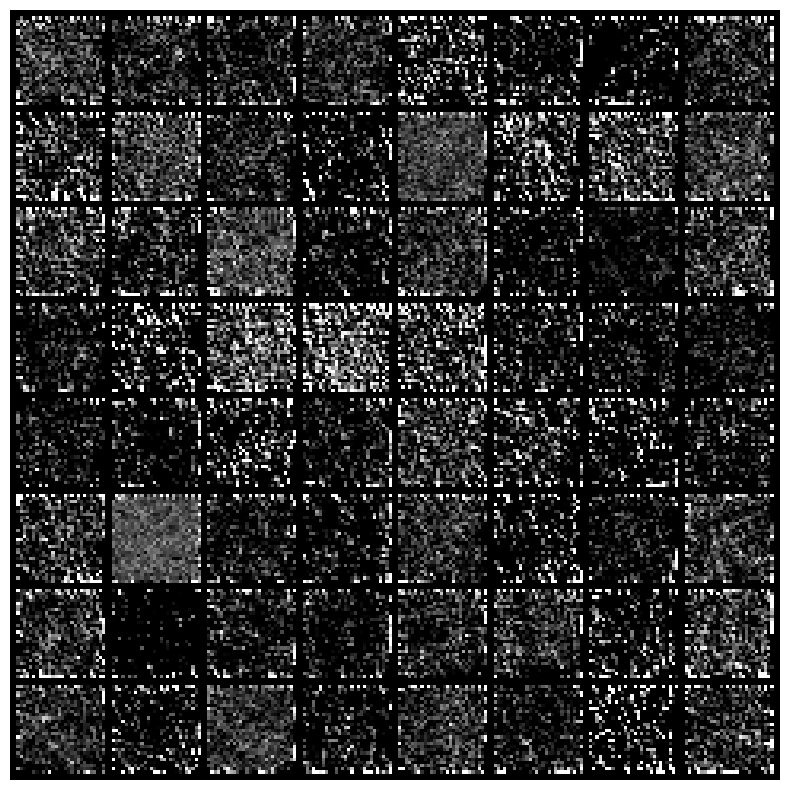

In [ ]:
visualize_png_images(gen_rep)